# From a mean size to a curve: the Rosin-Rammler distribution and the uniformity index

**Question:** What does the uniformity index do to the size curve?

**Level 1: Fundamentals** · Needs: 02-classical-prediction/01-the-classical-equation-on-one-blast · Reading time: about 25 minutes

## Objectives

A crusher is specified against a percentile, usually the P80, and the classical equation returns only a mean size. The Rosin-Rammler curve closes that gap with one extra number, the uniformity index, and this notebook isolates what that number does while the mean size stays fixed.

By the end you will have:

- built the index from the pattern of the Enusa blast factor by factor, including the mixed units that trip most readers;
- drawn the size curve of that blast and read its P20, P50 and P80 from it;
- moved the index with the mean size held fixed and measured how far the fines and the oversize travel;
- placed all 91 blasts that have a geometry on that axis and checked which sizes depend on the index alone.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

One cell does all the preparation: it imports the packages, prints their installed versions so the output records which engine produced every number below, defines the table helper and loads the 97 training blasts.

In [1]:
# Imports, the versions behind every number below, a small table helper and the corpus
import json
from importlib.metadata import version
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")


def show_table(columns, rows):
    # pandas is not part of the notebook environment, so a table is a plain HTML table
    head = "".join(f"<th>{c}</th>" for c in columns)
    body = "".join("<tr>" + "".join(f"<td>{v}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))


CASE = Path("../../../data/derived/real-enusa/case.json")
train = bf.load_training_corpus()

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The corpus and the reconstructed patterns | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The equations of the curve and of the uniformity index | Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (Eqs. 5 and 7) | the equations are reproduced with citation | `bf.rosin_rammler`, `bf.cunningham_uniformity_index` |
| The Enusa case, to name its representative blast | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/real-enusa/case.json`, field `representative_blast_id` |

No dataset held for this work records a measured size distribution: only the mean `x50` of each blast is measured. Every curve in this notebook is model output, and the notebook says so where it matters.

## Method

The Rosin-Rammler curve gives the fraction of the blasted rock that passes a mesh of size `x` (Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013, Eq. 5):

```
P(x) = 1 - exp( -0.693 * (x / x50)^n )
```

The 0.693 is `ln 2`, which makes `x50` the size through which half the mass passes. The exponent `n` is the uniformity index. A large `n` means a narrow size range, a small `n` a wide one with both oversize and fines. Solving the equation for the size that passes a fraction `p` gives `x_p = x50 * (ln(1 / (1 - p)) / ln 2)^(1/n)`, so the ratio of any percentile to the mean size depends on `n` alone. That closed form is what the last figure checks against the engine.

Cunningham's 1987 index (Eq. 7 of the same paper) computes `n` from the pattern:

```
n = (2.2 - 14 B/d) * sqrt((1 + S/B) / 2) * (1 - W/B) * (|BCL - CCL| / L + 0.1)^0.1 * (L / H)
```

with burden `B` and spacing `S` in metres, hole diameter `d` in **millimetres**, drilling deviation `W`, charge length `L`, bench height `H` and the bottom and column charge lengths `BCL` and `CCL`. The mixed units are the trap: `B/d` here is about 0.027, not the dimensionless 27 that the corpus tabulates. The engine takes one continuous column, so the charge-distribution term is a constant. What to look for: which factor moves `n`, and what a change in `n` does to the P20 and the P80.

### Step 1: the blast and its pattern

The Enusa case names a representative blast. The cell reads its identifier from the case file, takes the blast from the corpus, reconstructs its absolute pattern from the published ratios and asks the classical equation for the mean size. The table lists the inputs of the index with their units, and the two ways the corpus can express B/d.

In [2]:
# The Enusa case names its representative blast; read its pattern and the classical mean size
blast_id = json.loads(CASE.read_text(encoding="utf-8"))["representative_blast_id"]
blast = next(b for b in train if b.blast_id == blast_id)
pattern = bf.reconstruct_pattern(blast)
x50 = bf.Kuznetsov().predict_one(blast).x50_m

rows = [
    ("burden B", f"{pattern.burden_m:.3f}", "m"),
    ("spacing S", f"{pattern.spacing_m:.3f}", "m"),
    ("hole diameter d", f"{pattern.hole_diameter_mm:.0f}", "mm"),
    ("bench height H", f"{pattern.bench_height_m:.3f}", "m"),
    ("charge length L", f"{pattern.charge_length_m:.3f}", "m"),
    ("drilling deviation W", f"{pattern.drill_deviation_m:.3f}", "m"),
    ("B / d", f"{pattern.burden_m / pattern.hole_diameter_mm:.4f}", "m per mm"),
    ("B/d as the corpus tabulates it", f"{blast.B_over_D}", "dimensionless"),
    ("classical mean size x50", f"{x50:.4f}", "m"),
    ("measured mean size", f"{blast.x50_m}", "m"),
]
show_table(["input", "value", "unit"], rows)

input,value,unit
burden B,4.500,m
spacing S,5.579,m
hole diameter d,165,mm
bench height H,5.984,m
charge length L,2.475,m
drilling deviation W,0.000,m
B / d,0.0273,m per mm
B/d as the corpus tabulates it,27.27,dimensionless
classical mean size x50,0.4399,m
measured mean size,0.37,m


The pattern is a bench of about 6 m with a 165 mm hole, and the classical mean size is the number that anchors every curve below. The two B/d rows are the unit trap in numbers: the quotient in metres per millimetre is the one the index uses, and the corpus ratio is 1000 times larger. The predicted mean size also differs from the measured one, which matters later: the curve is a model of the blast, not a record of it.

### Step 2: the index, factor by factor

The index is a product of five factors. The cell computes each one from the pattern, multiplies them and puts the engine's `cunningham_uniformity_index` beside the product, so the equation is no longer a black box and the 0.1 exponent term is visible as the constant it is for a single column.

In [3]:
# Cunningham's index factor by factor, and the engine's value beside the product
def index_factors(p):
    return {
        "2.2 - 14 B/d": 2.2 - 14 * p.burden_m / p.hole_diameter_mm,
        "sqrt((1 + S/B) / 2)": ((1 + p.spacing_m / p.burden_m) / 2) ** 0.5,
        "1 - W/B": 1 - p.drill_deviation_m / p.burden_m,
        "(|BCL - CCL| / L + 0.1)^0.1, one column": 0.1 ** 0.1,
        "L / H": p.charge_length_m / p.bench_height_m,
    }


factors = index_factors(pattern)
n_engine = bf.cunningham_uniformity_index(pattern)
rows = [(name, f"{value:.4f}") for name, value in factors.items()]
rows.append(("product of the five factors", f"{np.prod(list(factors.values())):.4f}"))
rows.append(("bf.cunningham_uniformity_index", f"{n_engine:.4f}"))
show_table(["factor", "value"], rows)

factor,value
2.2 - 14 B/d,1.8182
sqrt((1 + S/B) / 2),1.0583
1 - W/B,1.0000
"(|BCL - CCL| / L + 0.1)^0.1, one column",0.7943
L / H,0.4135
product of the five factors,0.6321
bf.cunningham_uniformity_index,0.6321


The five factors multiply to 0.6321 and the engine returns 0.6321, so the equation is understood as the engine applies it. Two factors are neutral here: the drilling deviation `W` is zero for every reconstructed pattern, which makes `1 - W/B` equal to 1.0000, and the charge-distribution term is the constant 0.7943 for a single column. The factor that pulls the index below 1 is `L / H` at 0.4135: the charge fills only 2.475 m of a bench of 5.984 m, and the stemming takes the rest. What the table does not show is how far each factor can move, which step 5 measures on the whole corpus.

### Step 3: the curve and what a crusher reads from it

`rosin_rammler` evaluates the curve on the engine's shared logarithmic sieve grid, from 0.1 mm to 3 m, and returns a `SizeDistribution` that can be asked for the size passing any fraction. The cell reads the P20, the P50 and the P80, the characteristic size through which 63.2 percent passes, and the fraction that passes the measured mean size, then draws the curve with the three percentiles marked.

passing,size (m)
P20,0.0732
P50,0.4399
P80,1.6679


characteristic size, 63.2 % passes: 0.7855 m
fraction passing the measured mean size (0.37 m): 0.463


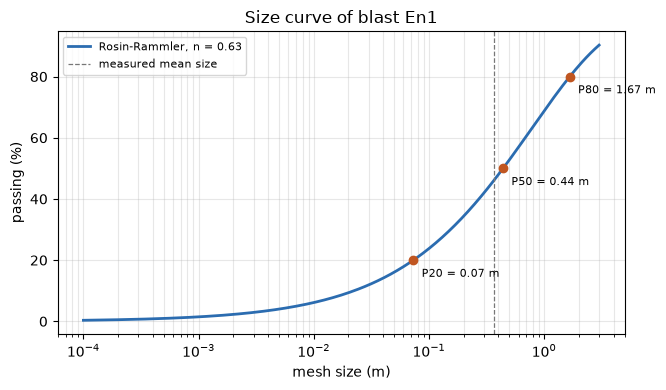

In [4]:
# Build the Rosin-Rammler curve of the blast and mark the sizes a crusher reads from it
curve = bf.rosin_rammler(x50, n_engine)
marks = {fraction: curve.percentile_m(fraction) for fraction in (0.2, 0.5, 0.8)}
show_table(["passing", "size (m)"], [(f"P{int(f * 100)}", f"{m:.4f}") for f, m in marks.items()])
print(f"characteristic size, 63.2 % passes: {curve.detail['characteristic_size_m']:.4f} m")
print(f"fraction passing the measured mean size ({blast.x50_m} m): {curve.passing_at(blast.x50_m):.3f}")

fig, ax = plt.subplots(figsize=(6.8, 4))
ax.plot(curve.sizes_m, [100 * p for p in curve.passing], color="#2b6cb0", lw=2,
        label=f"Rosin-Rammler, n = {n_engine:.2f}")
for fraction, size in marks.items():
    ax.plot([size], [100 * fraction], "o", color="#c05621")
    ax.annotate(f"P{int(fraction * 100)} = {size:.2f} m", (size, 100 * fraction),
                xytext=(6, -12), textcoords="offset points", fontsize=8)
ax.axvline(blast.x50_m, color="#777", lw=0.9, ls="--", label="measured mean size")
ax.set_xscale("log")
ax.set_xlabel("mesh size (m)")
ax.set_ylabel("passing (%)")
ax.set_title(f"Size curve of blast {blast_id}")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()

The curve is a smooth S on the logarithmic axis, and the three marks read what a crusher would specify: 20 percent of the mass is finer than 0.0732 m, half is finer than 0.4399 m and 80 percent is finer than 1.6679 m. The characteristic size, through which 63.2 percent passes, is 0.7855 m, and the measured mean size of 0.37 m has only 0.463 of the mass below it on this curve, so the model is a little coarser than the measurement. The figure does not show a measured size distribution, because none exists for this blast: only the mean size was measured, and the whole shape comes from `n` = 0.63. What follows is the question of how that shape would change with `n`.

### Step 4: moving the index with the mean size fixed

To isolate the index, the cell builds six curves with the same mean size and `n` from 0.5 to 3, a range that covers the values the corpus produces. The table gives the P20, the P50, the P80 and their ratio, and the figure overlays the curves with the mean size marked.

n,P20 (m),P50 (m),P80 (m),P80 / P20
0.5,0.0456,0.4399,2.3717,52.0
0.75,0.0970,0.4399,1.3526,13.9
1.0,0.1416,0.4398,1.0214,7.2
1.5,0.2066,0.4398,0.7715,3.7
2.0,0.2495,0.4398,0.6703,2.7
3.0,0.3013,0.4398,0.5826,1.9


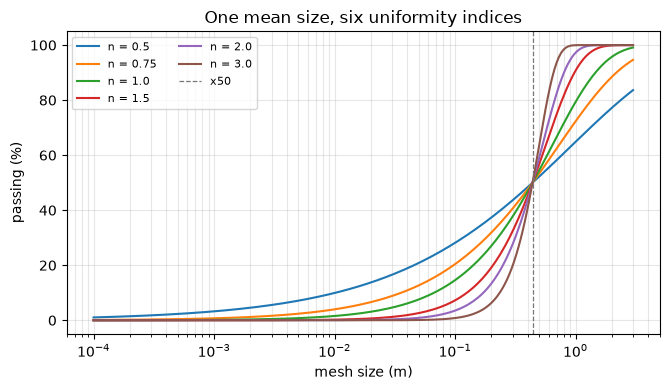

In [5]:
# Same mean size, six uniformity indices: the curve and the sizes it implies
indices = [0.5, 0.75, 1.0, 1.5, 2.0, 3.0]
sweep = {n: bf.rosin_rammler(x50, n) for n in indices}
rows = []
for n, shape in sweep.items():
    p20, p80 = shape.percentile_m(0.2), shape.percentile_m(0.8)
    rows.append((n, f"{p20:.4f}", f"{shape.percentile_m(0.5):.4f}", f"{p80:.4f}", f"{p80 / p20:.1f}"))
show_table(["n", "P20 (m)", "P50 (m)", "P80 (m)", "P80 / P20"], rows)

fig, ax = plt.subplots(figsize=(6.8, 4))
for n, shape in sweep.items():
    ax.plot(shape.sizes_m, [100 * p for p in shape.passing], label=f"n = {n}")
ax.axvline(x50, color="#777", lw=0.9, ls="--", label="x50")
ax.set_xscale("log")
ax.set_xlabel("mesh size (m)")
ax.set_ylabel("passing (%)")
ax.set_title("One mean size, six uniformity indices")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()

The six curves cross at the mean size and fan out on both sides, which is the whole effect of the index. At `n` = 0.5 the P20 is 0.0456 m and the P80 is 2.3717 m, a ratio of 52.0; at `n` = 3 the P20 rises to 0.3013 m and the P80 falls to 0.5826 m, a ratio of 1.9. The P50 stays at 0.4399 m or 0.4398 m in every row, so a change of `n` redistributes mass between the fines and the oversize without touching the median. The figure does not say which `n` a given blast has, and it does not say which curve is closer to the truth; that needs the pattern, which step 5 supplies.

### Step 5: the index across the corpus

The index depends on the pattern only, so it can be computed for every blast with a geometry (the other six publish no hole diameter, and the engine refuses to invent one). The cell reuses the factor function of step 2 on all of them, tabulates the range of each factor and counts the blasts inside the usual range of 0.7 to 2 that Amoako, Jha and Zhong state.

In [6]:
# The index of every blast with a geometry, and what each of its factors does across the corpus
with_geometry = [b for b in train if bf.has_absolute_geometry(b)]
patterns = [bf.reconstruct_pattern(b) for b in with_geometry]
n_all = np.array([bf.cunningham_uniformity_index(p) for p in patterns])
per_blast = [index_factors(p) for p in patterns]
rows = []
for name in per_blast[0]:
    values = np.array([f[name] for f in per_blast])
    rows.append((name, f"{values.min():.3f}", f"{np.median(values):.3f}", f"{values.max():.3f}"))
rows.append(("n (the product)", f"{n_all.min():.3f}", f"{np.median(n_all):.3f}", f"{n_all.max():.3f}"))
show_table(["factor", "minimum", "median", "maximum"], rows)
usual = int(((n_all >= 0.7) & (n_all <= 2)).sum())
print(f"blasts with a geometry: {len(n_all)} | inside the usual range 0.7 to 2: {usual}")

factor,minimum,median,maximum
2.2 - 14 B/d,1.647,1.818,1.948
sqrt((1 + S/B) / 2),1.000,1.049,1.173
1 - W/B,1.000,1.000,1.000
"(|BCL - CCL| / L + 0.1)^0.1, one column",0.794,0.794,0.794
L / H,0.120,0.632,0.900
n (the product),0.184,0.950,1.362


blasts with a geometry: 91 | inside the usual range 0.7 to 2: 62


Across the 91 blasts the index runs from 0.184 to 1.362 with a median of 0.950, and 62 of them fall inside the usual range of 0.7 to 2, so the rest sit below it and none reaches the upper half of that range. The table says why: the burden-to-diameter factor only moves between 1.647 and 1.948, and the spacing factor between 1.000 and 1.173, while `L / H` ranges from 0.120 to 0.900. The index of this corpus is therefore set almost entirely by how much of the bench is charged, not by the burden-to-diameter ratio that the equation seems to emphasise. The table does not show whether the corpus is typical of other mines; the usual range comes from the literature and not from this data.

### Step 6: the tail across the corpus

Last, every blast gets its own curve from its own mean size and index, and the ratio of its P80 to its mean size is plotted against the index. If the closed form of the method section is right, the points fall on a single line whatever the mean size, because the mean size cancels. The left panel shows how the indices themselves are distributed against the usual range.

blasts whose closed-form P80 lies beyond the 3 m grid: 16 of 91
largest gap between the engine and the closed form on the others: 3.5e-04
P80 / mean size, the others: min 1.86 | median 2.37 | max 5.73


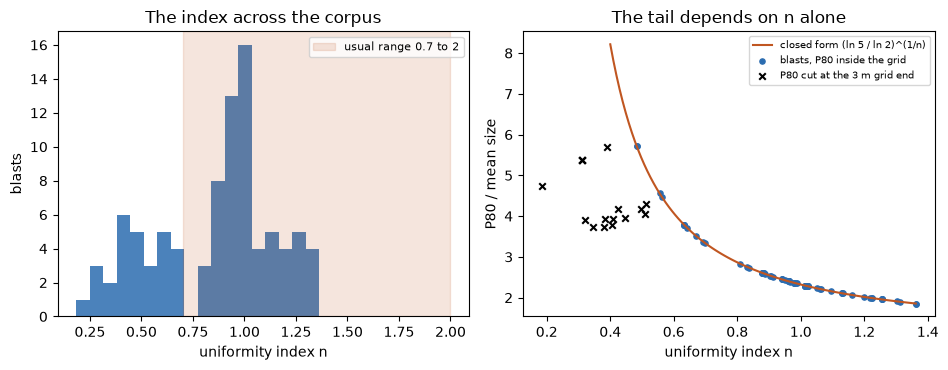

In [7]:
# Every blast's P80 against its mean size, from its own curve, beside the index distribution
x50_all = np.array([bf.Kuznetsov().predict_one(b).x50_m for b in with_geometry])
p80_ratio = np.array([bf.rosin_rammler(x, n).percentile_m(0.8) / x for x, n in zip(x50_all, n_all)])
closed_form = (np.log(5) / np.log(2)) ** (1 / n_all)
# A curve that stays under 80 percent on the sieve grid has its P80 read at the last grid size
beyond_grid = closed_form * x50_all > bf.sieve_grid()[-1]
gap = np.abs(p80_ratio - closed_form)[~beyond_grid].max()
print(f"blasts whose closed-form P80 lies beyond the 3 m grid: {int(beyond_grid.sum())} of {len(n_all)}")
print(f"largest gap between the engine and the closed form on the others: {gap:.1e}")
inside = p80_ratio[~beyond_grid]
print(f"P80 / mean size, the others: min {inside.min():.2f}",
      f"| median {np.median(inside):.2f} | max {inside.max():.2f}")

fig, (left, right) = plt.subplots(1, 2, figsize=(9.6, 3.8))
left.hist(n_all, bins=18, color="#2b6cb0", alpha=0.85)
left.axvspan(0.7, 2.0, color="#c05621", alpha=0.15, label="usual range 0.7 to 2")
left.set_xlabel("uniformity index n")
left.set_ylabel("blasts")
left.set_title("The index across the corpus")
left.legend(fontsize=8)
n_line = np.linspace(0.4, n_all.max(), 100)
right.plot(n_line, (np.log(5) / np.log(2)) ** (1 / n_line), color="#c05621", lw=1.5,
           label="closed form (ln 5 / ln 2)^(1/n)")
right.scatter(n_all[~beyond_grid], inside, s=14, color="#2b6cb0",
              label="blasts, P80 inside the grid")
right.scatter(n_all[beyond_grid], p80_ratio[beyond_grid], s=22, marker="x", color="black",
              label="P80 cut at the 3 m grid end")
right.set_xlabel("uniformity index n")
right.set_ylabel("P80 / mean size")
right.set_title("The tail depends on n alone")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

The left panel confirms the table: the indices bunch between 0.7 and 1.4, with a second group of smaller values below 0.7. In the right panel, 75 blasts lie on the closed-form line within 3.5e-04 and the ratio of P80 to mean size falls from 5.73 at the lowest index to 1.86 near the highest, with a median of 2.37; the mean size is irrelevant to that ratio. The 16 crosses are blasts whose closed-form P80 lies beyond the 3 m sieve grid: the engine reads such a P80 at the grid's last size, so below an index of about 0.5 the curve's coarse end is cut off, not measured. The figure does not show whether any blast really breaks to such coarse tails; the next notebook introduces the in situ block that bounds them.

## Results

**Answer:** the uniformity index sets the width of the size curve and leaves its median where the mean size puts it. With the mean size fixed at 0.4399 m, raising `n` from 0.5 to 3 lifts the P20 from 0.0456 m to 0.3013 m and lowers the P80 from 2.3717 m to 0.5826 m. For the Enusa blast `n` is 0.6321, which gives a P20 of 0.0732 m and a P80 of 1.6679 m. Across the 91 blasts with a geometry the index runs from 0.184 to 1.362, 62 of them inside the usual 0.7 to 2 range, and it is driven mostly by the charged fraction of the bench (`L / H`, from 0.120 to 0.900). For the 75 blasts whose P80 lies inside the sieve grid, the P80 is exactly the mean size times a function of `n`, with a median ratio of 2.37.

**What this does not show.** No measured size distribution exists in the corpus, so none of these curves is validated: they are the classical model's shape, and the claim that a larger `n` is a narrower distribution is a property of the equation, not a finding about the rock. The index also takes the drilling deviation as zero for every blast, which removes one of its own factors. Finally, the engine reads a P80 beyond 3 m at 3 m, so the 16 lowest-index blasts have a coarse end that this notebook cannot report.

## Summary

- The index `n` is the width of the Rosin-Rammler curve: at a fixed mean size it trades fines against oversize and leaves the P50 alone.
- Cunningham's index is a product of five factors with mixed units; in this corpus the charged fraction `L / H` drives it.
- Every P80 is the mean size times a function of `n` alone, until the curve leaves the 3 m sieve grid.
- Next: notebook 02 compares this curve with the Swebrec and crush-zone forms and caps it at the in situ block.

## References

- Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (Eqs. 5 and 7)
- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/